In [1]:
%pip install tensorflow scikit-learn matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Training Data: (60000, 28, 28)
Testing Data: (10000, 28, 28)
Flattened Training Data: (60000, 784)
One-Hot Labels: (60000, 10)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4992 - loss: 2.0488 - val_accuracy: 0.7108 - val_loss: 1.7887
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7084 - loss: 1.6083 - val_accuracy: 0.7818 - val_loss: 1.3788
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7661 - loss: 1.2702 - val_accuracy: 0.8268 - val_loss: 1.0830
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7992 - loss: 1.0377 - val_accuracy: 0.8523 - val_loss: 0.8867
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8209 - loss: 0.8831 - val_accuracy: 0.8667 - val_loss: 0.7553
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8389 - loss: 0.7973

Test Loss: 0.7972990870475769
Test Accuracy: 83.89000296592712 %
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.95      0.92       980
           1       0.83      0.97      0.90      1

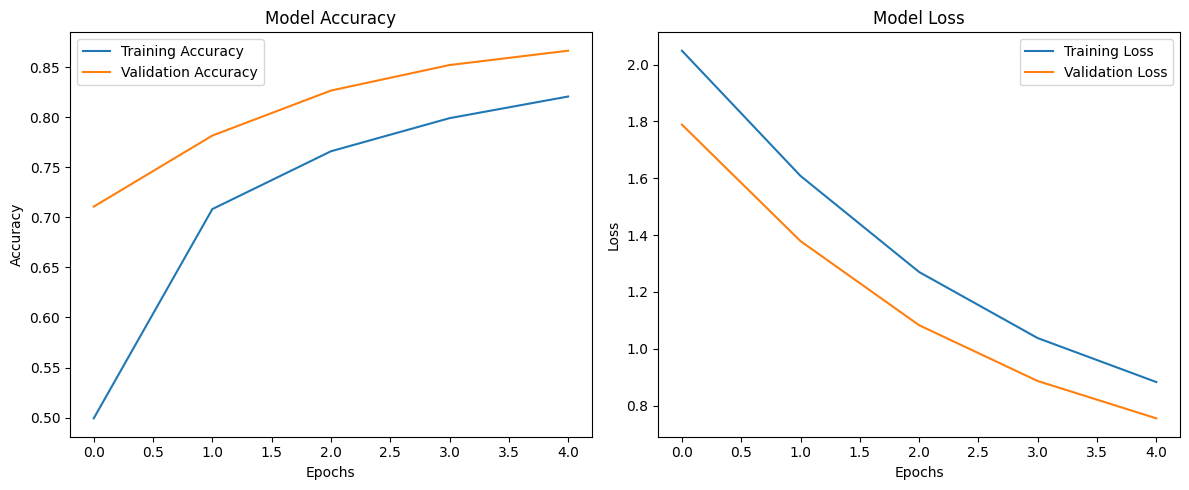

Actual: 7 | Predicted: 7
Actual: 2 | Predicted: 2
Actual: 1 | Predicted: 1
Actual: 0 | Predicted: 0
Actual: 4 | Predicted: 4


In [2]:

# EXPERIMENT 2: FEEDFORWARD NEURAL NETWORK

# 1. Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import models, layers, optimizers, datasets, backend
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import classification_report

# 2. Set backend and random seed
backend.set_floatx('float32')
np.random.seed(42)
tf.random.set_seed(42)

# 3. Load MNIST dataset
(X_train, y_train), (X_test, y_test) = datasets.mnist.load_data()

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# 4. Flatten the images (28x28 to 784)
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

# 5. Normalize pixel values (0 to 1)
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# 6. Convert labels into one-hot encoding
lb = LabelBinarizer()

y_train = lb.fit_transform(y_train)
y_test = lb.transform(y_test)

print("Flattened Training Data:", X_train.shape)
print("One-Hot Labels:", y_train.shape)

# 7. Define Feedforward Neural Network
model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='sigmoid'),
    layers.Dense(10, activation='softmax')
])

# 8. Compile the model using SGD
model.compile(
    optimizer=optimizers.SGD(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

# 9. Train the model
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

# 10. Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

# 11. Predict test data
y_pred = model.predict(X_test)

# Convert probabilities into class labels
y_pred = np.argmax(y_pred, axis=1)
y_actual = np.argmax(y_test, axis=1)

print("\nClassification Report:")
print(classification_report(
    y_actual,
    y_pred,
    target_names=[str(i) for i in range(10)]
))

# 12. Plot training and validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# 13. Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# 14. Display sample predictions
for i in range(5):
    print("Actual:", y_actual[i], "| Predicted:", y_pred[i])
